# Substructure Analysis: 104 + 66 Caspase-Active Compounds

**Section 1** — 104 compounds from the fully-tested set (all 14 cell lines), active in ≥1 cell line  
**Section 2** — 66 compounds tested only in CHO-K1 + HepG2, active in both  
**Section 3** — Combined 170 compounds: shared structural families across both groups

For each group: UMAP chemical space → DBSCAN clustering → MCS core per cluster → representative structures

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
import umap
import warnings
warnings.filterwarnings('ignore')

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    return fps, np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)

def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(8, 6))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6.5, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

def get_mcs_core(mols):
    """Return MCS core mol, or None if <2 mols or no common core found."""
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                         completeRingsOnly=True, timeout=10)
    if mcs and mcs.numAtoms > 0:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

def draw_cluster_reps(dataset, name_map, title, mols_per_row=5, img_size=(280, 230),
                      max_per_cluster=12):
    """Draw one representative + MCS core per cluster."""
    from IPython.display import display
    import pubchempy as pcp

    reps, legs, highlights = [], [], []
    cl_name_map = {}
    print(f'Fetching PubChem names for {title}...')

    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub   = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps   = sub['fp'].tolist()
        avg   = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep   = sub.loc[int(np.argmax(avg))]
        cid   = int(rep['PUBCHEM_CID'])
        try:
            c_   = pcp.Compound.from_cid(cid)
            syns = c_.synonyms or []
            short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
            name  = short[0] if short else (syns[0][:28] if syns else str(cid))
        except Exception:
            name = str(cid)
        cl_name_map[cl] = name

        # MCS core panel
        cluster_mols = sub.head(max_per_cluster)['mol'].tolist()
        core = get_mcs_core(cluster_mols)
        if core is not None:
            reps.append(core)
            legs.append(f'C{cl} (n={len(sub)}) ★ Core ★')
            highlights.append([])

        # Representative molecule
        reps.append(rep['mol'])
        legs.append(f'C{cl} (n={len(sub)})\n{name} [CID {cid}]')
        match = rep['mol'].GetSubstructMatch(core) if core is not None else []
        highlights.append(list(match))
        print(f'  Cluster {cl:2d} (n={len(sub):3d})  {name}  [CID {cid}]')

    if not reps:
        print('No clusters found — all compounds are structurally unique.')
        return cl_name_map

    img = Draw.MolsToGridImage(reps, molsPerRow=mols_per_row, subImgSize=img_size,
                               legends=legs, highlightAtomLists=highlights,
                               returnPNG=False)
    display(img)
    return cl_name_map

def umap_by_cluster(dataset, cl_name_map, title):
    fig, ax = plt.subplots(figsize=(9, 7))
    cmap = plt.cm.tab10
    noise = dataset[dataset['cluster'] == -1]
    ax.scatter(noise['umap_x'], noise['umap_y'], c='#cccccc',
               s=35, edgecolors='none', alpha=0.5, label=f'unique / noise (n={len(noise)})')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub = dataset[dataset['cluster'] == cl]
        name = cl_name_map.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=70, edgecolors='black', linewidths=0.5, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    for _, row in dataset.iterrows():
        ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()

print('Setup complete.')

Setup complete.


---
## Load Data

In [7]:
# ── Main assay table ──────────────────────────────────────────────────────────
df = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
ASSAY_COLS = [c for c in df.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

# ── Build a combined SMILES lookup from all cleaned datasets ──────────────────
smi_dfs = []
for fname in os.listdir(BASE + 'cleaned_datasets'):
    if not fname.endswith('.csv'):
        continue
    try:
        tmp = pd.read_csv(BASE + 'cleaned_datasets/' + fname,
                          usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                          low_memory=False)
        smi_dfs.append(tmp)
    except Exception:
        pass

smiles_df = (pd.concat(smi_dfs)
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID')
               .reset_index(drop=True))
print(f'SMILES lookup: {len(smiles_df)} unique compounds')

# ── Group 1: 104 — fully tested (all 14 assays), active in ≥1 cell line ───────
fully_tested = df[df[ASSAY_COLS].notna().all(axis=1)].copy()
fully_tested['n_active'] = (fully_tested[ASSAY_COLS] == 'Active').sum(axis=1)
cids_104 = fully_tested[fully_tested['n_active'] >= 1]['PUBCHEM_CID'].tolist()
print(f'Group 104: {len(cids_104)} compounds (fully tested, active in ≥1 of 14 cell lines)')

# ── Group 2: 66 — active in CHO-K1 + HepG2 only ─────────────────────────────
cids_66 = df[df['behavior'] == 'Active']['PUBCHEM_CID'].tolist()
print(f'Group 66:  {len(cids_66)} compounds (CHO-K1 + HepG2 active, not tested elsewhere)')
print(f'Overlap:   {len(set(cids_104) & set(cids_66))} (should be 0)')

SMILES lookup: 8777 unique compounds
Group 104: 104 compounds (fully tested, active in ≥1 of 14 cell lines)
Group 66:  66 compounds (CHO-K1 + HepG2 active, not tested elsewhere)
Overlap:   0 (should be 0)


---
## Section 1 — 104 Compounds: Fully-Tested, Active in ≥1 Cell Line

These 104 compounds were tested in **all 14 cell lines** and showed caspase activation in at least one.
We colour-code by how many cell lines each compound activated.

In [8]:
g104 = (pd.DataFrame({'PUBCHEM_CID': cids_104})
          .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g104 = g104.merge(
    fully_tested[['PUBCHEM_CID', 'n_active']], on='PUBCHEM_CID', how='left')
g104['mol'] = g104['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g104 = g104[g104['mol'].notna()].reset_index(drop=True)

# Bin by activity breadth
def activity_bin(n):
    if n == 1:  return '1 cell line'
    if n <= 3:  return '2–3 cell lines'
    if n <= 7:  return '4–7 cell lines'
    return '8+ cell lines (pan-toxic)'

g104['activity_bin'] = g104['n_active'].apply(activity_bin)
g104['fp'], fp_matrix_104 = to_fp_matrix(g104['mol'].tolist())

print(g104['activity_bin'].value_counts())
print(f'\n{len(g104)} compounds with valid SMILES')

activity_bin
1 cell line                  62
2–3 cell lines               25
4–7 cell lines               13
8+ cell lines (pan-toxic)     4
Name: count, dtype: int64

104 compounds with valid SMILES


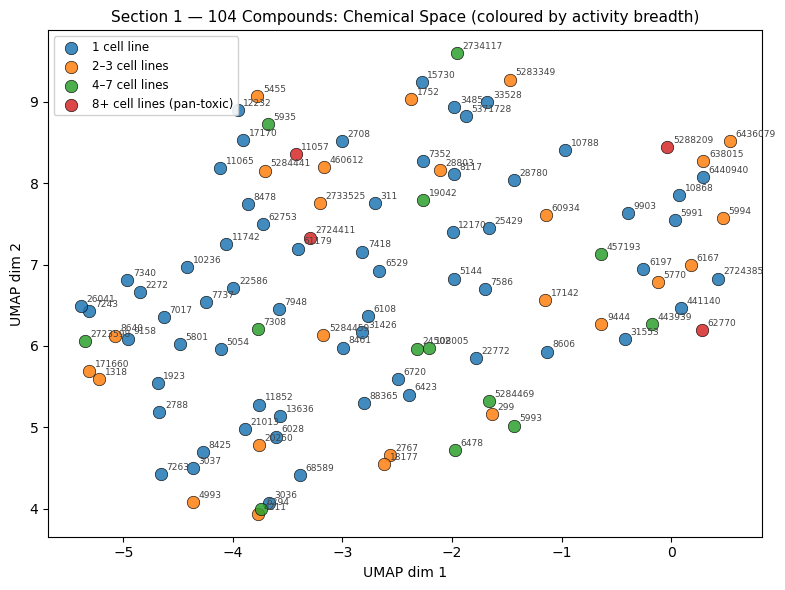

In [9]:
color_map_104 = {
    '1 cell line':            '#1f77b4',
    '2–3 cell lines':         '#ff7f0e',
    '4–7 cell lines':         '#2ca02c',
    '8+ cell lines (pan-toxic)': '#d62728',
}

emb_104 = plot_umap(
    fp_matrix_104,
    labels    = g104['activity_bin'].tolist(),
    title     = 'Section 1 — 104 Compounds: Chemical Space (coloured by activity breadth)',
    color_map = color_map_104,
    annotate  = g104['PUBCHEM_CID'].astype(int),
)
g104['umap_x'], g104['umap_y'] = emb_104[:, 0], emb_104[:, 1]

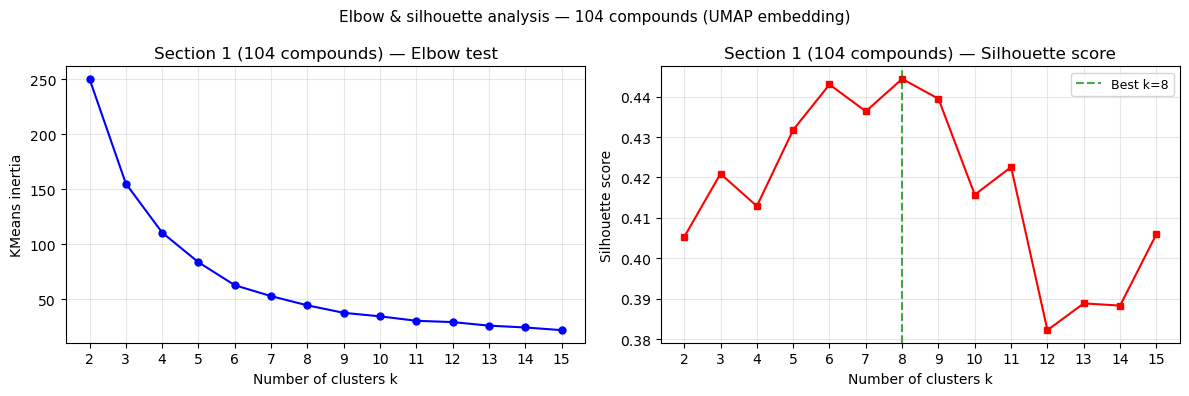

Peak silhouette score at k=8 — DBSCAN cluster count follows below.


In [10]:

# ── Elbow test (KMeans inertia + silhouette) on UMAP embedding ────────────────
# Justifies the number of clusters found by DBSCAN below.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(2, 16)
inertias_104, silhouettes_104 = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(emb_104)
    inertias_104.append(km.inertia_)
    silhouettes_104.append(silhouette_score(emb_104, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(list(K_RANGE), inertias_104, 'bo-', linewidth=1.5, markersize=5)
ax1.set_xlabel('Number of clusters k')
ax1.set_ylabel('KMeans inertia')
ax1.set_title('Section 1 (104 compounds) — Elbow test')
ax1.set_xticks(list(K_RANGE))
ax1.grid(True, alpha=0.3)

ax2.plot(list(K_RANGE), silhouettes_104, 'rs-', linewidth=1.5, markersize=5)
ax2.set_xlabel('Number of clusters k')
ax2.set_ylabel('Silhouette score')
ax2.set_title('Section 1 (104 compounds) — Silhouette score')
ax2.set_xticks(list(K_RANGE))
ax2.grid(True, alpha=0.3)

best_k_104 = list(K_RANGE)[int(np.argmax(silhouettes_104))]
ax2.axvline(best_k_104, color='green', linestyle='--', alpha=0.7, label=f'Best k={best_k_104}')
ax2.legend(fontsize=9)

plt.suptitle('Elbow & silhouette analysis — 104 compounds (UMAP embedding)', fontsize=11)
plt.tight_layout()
plt.show()
print(f'Peak silhouette score at k={best_k_104} — DBSCAN cluster count follows below.')

In [11]:
db_104 = DBSCAN(eps=0.45, min_samples=3).fit(emb_104)
g104['cluster'] = db_104.labels_
n_cl_104 = len(set(db_104.labels_)) - (1 if -1 in db_104.labels_ else 0)
print(f'DBSCAN (104): {n_cl_104} clusters, {(db_104.labels_ == -1).sum()} noise points')
print(pd.Series(db_104.labels_).value_counts().sort_index())

DBSCAN (104): 12 clusters, 18 noise points
-1     18
 0     16
 1      8
 2      5
 3     15
 4      4
 5     10
 6      5
 7      4
 8      6
 9      6
 10     3
 11     4
Name: count, dtype: int64


Fetching PubChem names for 104 fully-tested active compounds...
  Cluster  0 (n= 16)  O-AMINOPHENOL  [CID 5801]
  Cluster  1 (n=  8)  all-trans-Retinal  [CID 638015]
  Cluster  2 (n=  5)  Viscoat 335HP  [CID 28803]
  Cluster  3 (n= 15)  Malachite Green Oxalate  [CID 2724411]
  Cluster  4 (n=  4)  Benzene, 1-methyl-2,4-dinitro-  [CID 8461]
  Cluster  5 (n= 10)  Doxorubicin Hydrochloride  [CID 443939]
  Cluster  6 (n=  5)  Phenol, 2,3,5,6-tetrachloro-  [CID 13636]
  Cluster  7 (n=  4)  Dichlorophen  [CID 3037]
  Cluster  8 (n=  6)  Sodium dichromate dihydrate  [CID 108005]
  Cluster  9 (n=  6)  Phenol, 4-octyl-  [CID 15730]
  Cluster 10 (n=  3)  Technical chlordane  [CID 5993]
  Cluster 11 (n=  4)  p,p'-DDD  [CID 6294]


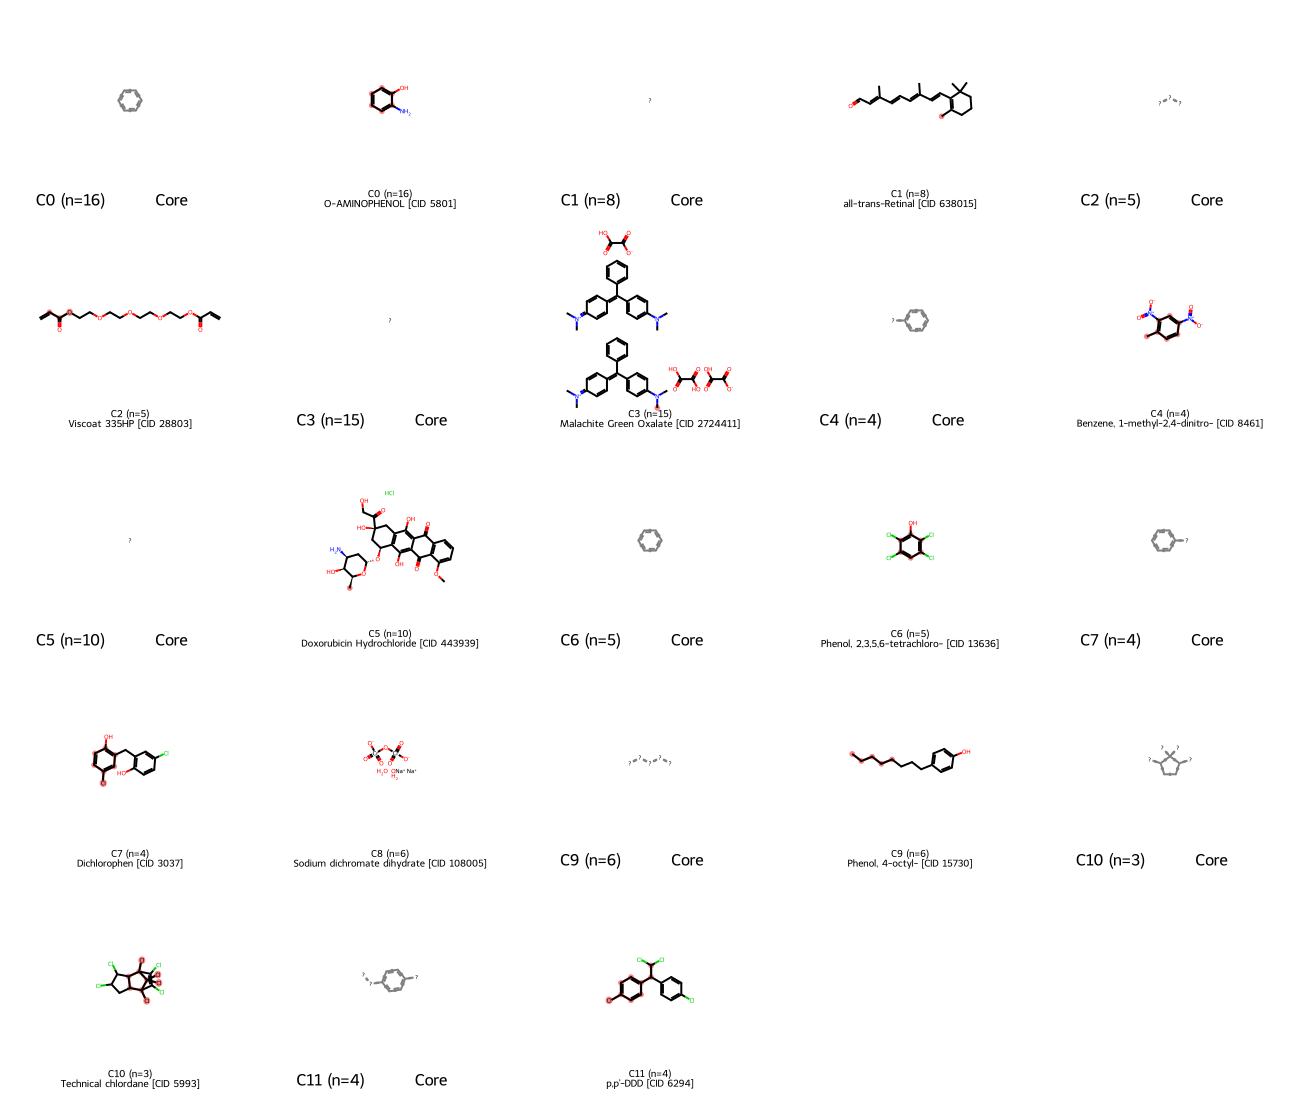

In [12]:
cl_name_104 = draw_cluster_reps(
    g104, {}, title='104 fully-tested active compounds',
    mols_per_row=5, img_size=(260, 220))

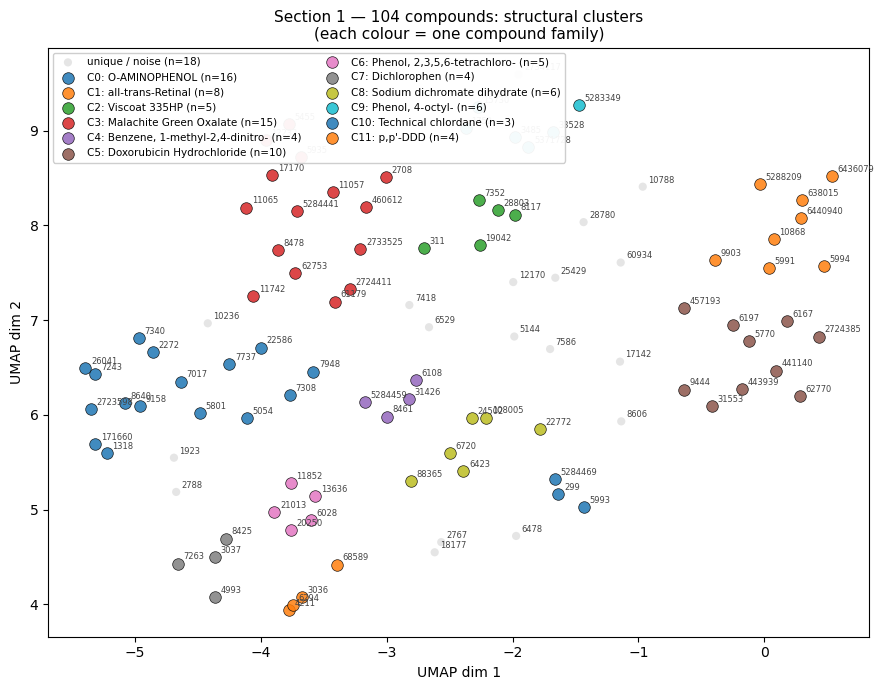

In [13]:
umap_by_cluster(
    g104, cl_name_104,
    title='Section 1 — 104 compounds: structural clusters\n(each colour = one compound family)')

### Section 1 — MCS Core Detail per Cluster
Change `CLUSTERS` to focus on specific clusters.

Drawing 86 panels across 12 cluster(s)


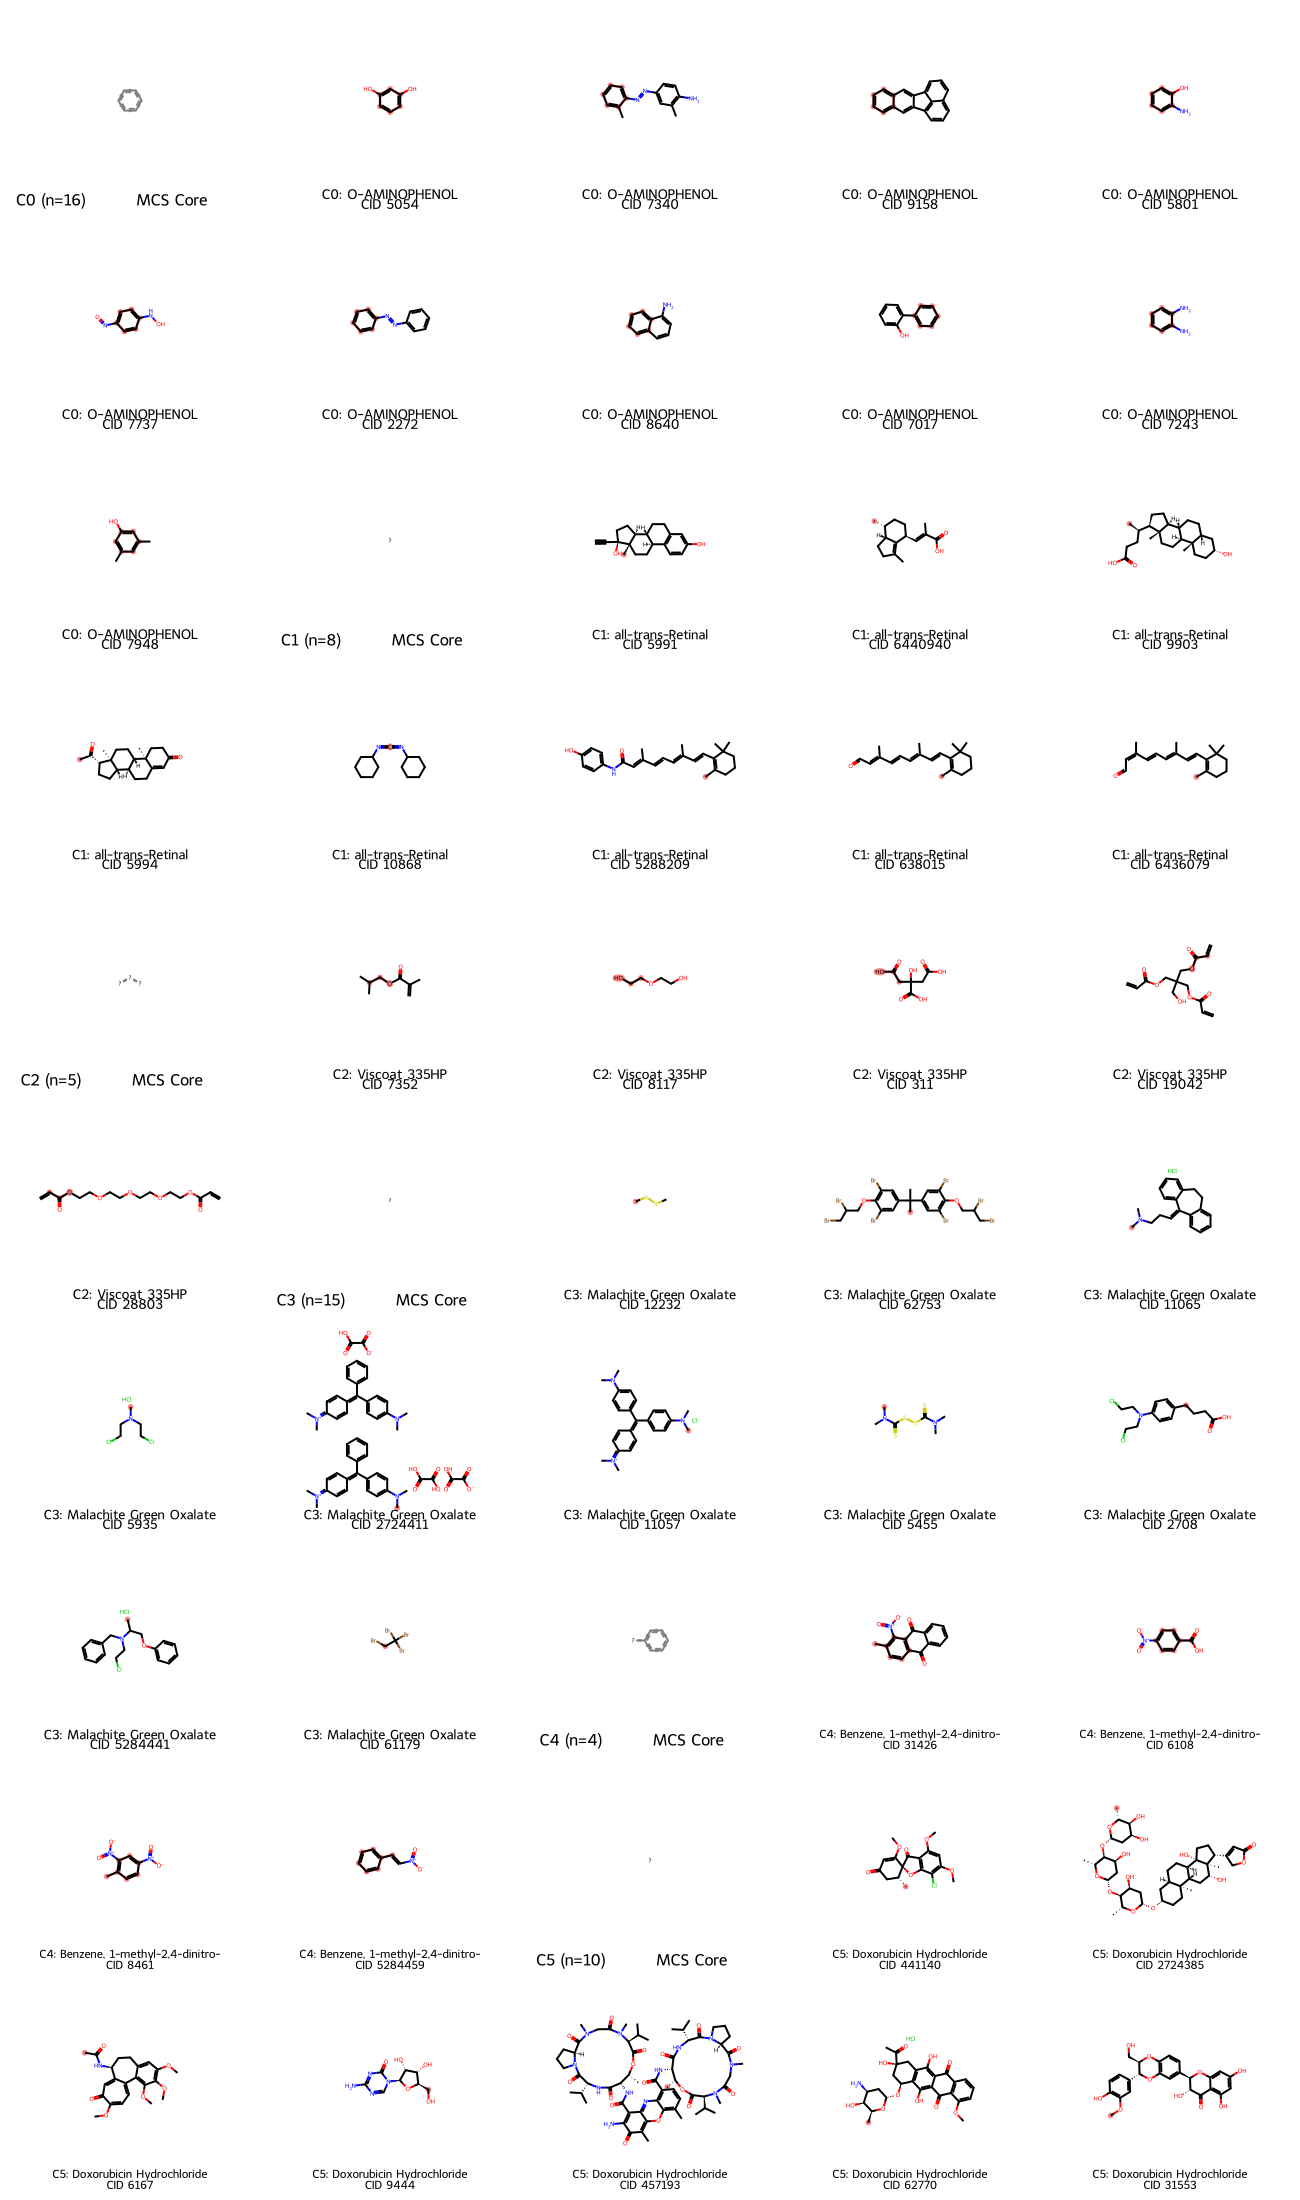

In [14]:
from IPython.display import display

CLUSTERS     = None      # None = all clusters; or e.g. [0, 1, 2]
MAX_PER_CL   = 10
MOLS_PER_ROW = 5

cluster_ids = sorted(c for c in g104['cluster'].unique() if c != -1)
if CLUSTERS is not None:
    cluster_ids = [c for c in cluster_ids if c in CLUSTERS]

mols, legends, highlights = [], [], []

for cl in cluster_ids:
    sub    = g104[g104['cluster'] == cl].reset_index(drop=True)
    shown  = sub.head(MAX_PER_CL)
    c_mols = shown['mol'].tolist()
    core   = get_mcs_core(c_mols)
    name   = cl_name_104.get(cl, f'Cluster {cl}')

    if core is not None:
        mols.append(core)
        legends.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        highlights.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols.append(mol)
        legends.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        highlights.append(list(match))

print(f'Drawing {len(mols)} panels across {len(cluster_ids)} cluster(s)')
img = Draw.MolsToGridImage(mols, molsPerRow=MOLS_PER_ROW, subImgSize=(260, 220),
                           legends=legends, highlightAtomLists=highlights,
                           returnPNG=False)
display(img)

---
## Section 2 — 66 Compounds: Active in CHO-K1 + HepG2 Only

These 66 compounds were **only tested in 2 cell lines** (CHO-K1 and HepG2) and were active in both.
Do they share structural families? Are they related to the 104?

In [15]:
g66 = (pd.DataFrame({'PUBCHEM_CID': cids_66})
         .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g66['mol'] = g66['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g66 = g66[g66['mol'].notna()].reset_index(drop=True)
g66['fp'], fp_matrix_66 = to_fp_matrix(g66['mol'].tolist())
print(f'{len(g66)} compounds with valid SMILES (out of 66)')

66 compounds with valid SMILES (out of 66)


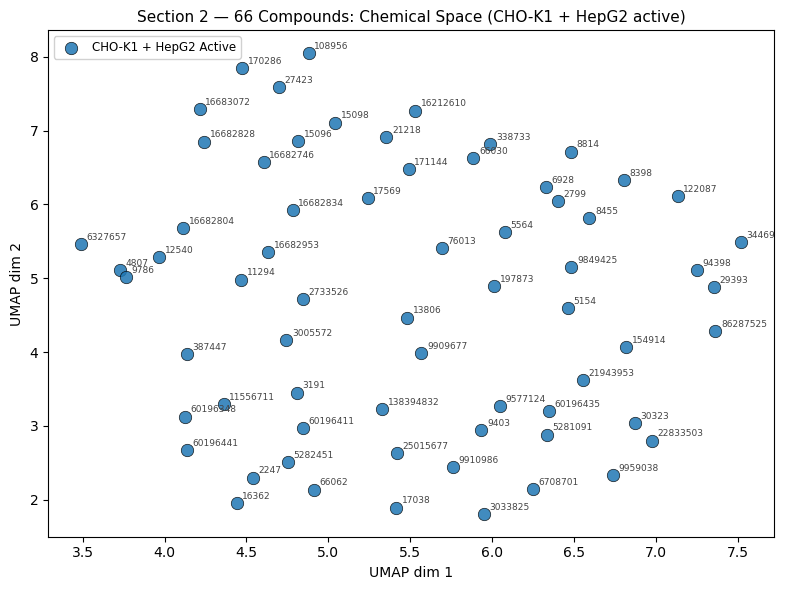

In [16]:
emb_66 = plot_umap(
    fp_matrix_66,
    labels   = ['CHO-K1 + HepG2 Active'] * len(g66),
    title    = 'Section 2 — 66 Compounds: Chemical Space (CHO-K1 + HepG2 active)',
    annotate = g66['PUBCHEM_CID'].astype(int),
)
g66['umap_x'], g66['umap_y'] = emb_66[:, 0], emb_66[:, 1]

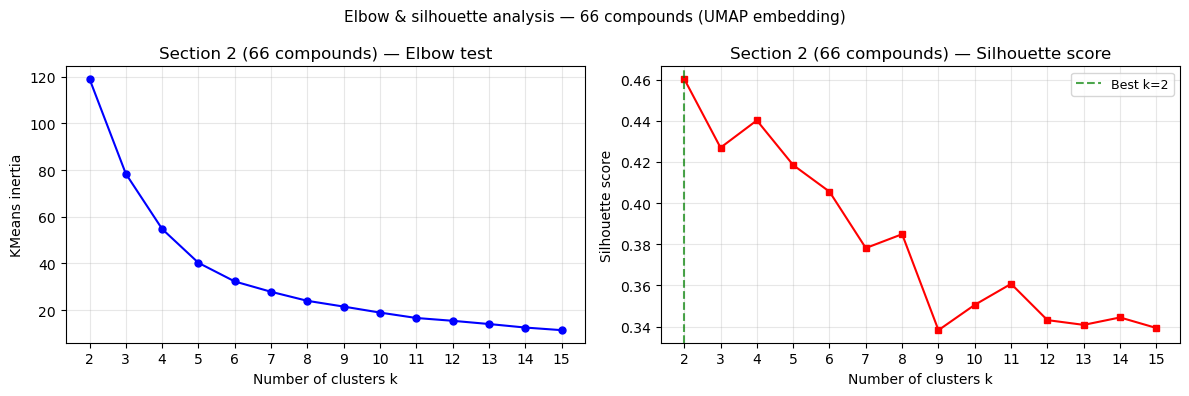

Peak silhouette score at k=2 — DBSCAN cluster count follows below.


In [17]:

# ── Elbow test (KMeans inertia + silhouette) on UMAP embedding ────────────────
K_RANGE_66 = range(2, min(16, len(g66)))
inertias_66, silhouettes_66 = [], []

for k in K_RANGE_66:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(emb_66)
    inertias_66.append(km.inertia_)
    silhouettes_66.append(silhouette_score(emb_66, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(list(K_RANGE_66), inertias_66, 'bo-', linewidth=1.5, markersize=5)
ax1.set_xlabel('Number of clusters k')
ax1.set_ylabel('KMeans inertia')
ax1.set_title('Section 2 (66 compounds) — Elbow test')
ax1.set_xticks(list(K_RANGE_66))
ax1.grid(True, alpha=0.3)

ax2.plot(list(K_RANGE_66), silhouettes_66, 'rs-', linewidth=1.5, markersize=5)
ax2.set_xlabel('Number of clusters k')
ax2.set_ylabel('Silhouette score')
ax2.set_title('Section 2 (66 compounds) — Silhouette score')
ax2.set_xticks(list(K_RANGE_66))
ax2.grid(True, alpha=0.3)

best_k_66 = list(K_RANGE_66)[int(np.argmax(silhouettes_66))]
ax2.axvline(best_k_66, color='green', linestyle='--', alpha=0.7, label=f'Best k={best_k_66}')
ax2.legend(fontsize=9)

plt.suptitle('Elbow & silhouette analysis — 66 compounds (UMAP embedding)', fontsize=11)
plt.tight_layout()
plt.show()
print(f'Peak silhouette score at k={best_k_66} — DBSCAN cluster count follows below.')

In [18]:
db_66 = DBSCAN(eps=0.45, min_samples=3).fit(emb_66)
g66['cluster'] = db_66.labels_
n_cl_66 = len(set(db_66.labels_)) - (1 if -1 in db_66.labels_ else 0)
print(f'DBSCAN (66): {n_cl_66} clusters, {(db_66.labels_ == -1).sum()} noise points')
print(pd.Series(db_66.labels_).value_counts().sort_index())

DBSCAN (66): 6 clusters, 42 noise points
-1    42
 0     4
 1     3
 2     5
 3     4
 4     5
 5     3
Name: count, dtype: int64


Fetching PubChem names for 66 CHO-K1+HepG2 active compounds...
  Cluster  0 (n=  4)  astemizole  [CID 2247]
  Cluster  1 (n=  3)  HSDB 5588  [CID 8455]
  Cluster  2 (n=  5)  TRIPHENYLTIN FLUORIDE  [CID 9786]
  Cluster  3 (n=  4)  NCGC00247733-01  [CID 5281091]
  Cluster  4 (n=  5)  TETRABUTYLTIN  [CID 15098]
  Cluster  5 (n=  3)  Phenol, 4-dodecyl-  [CID 66030]


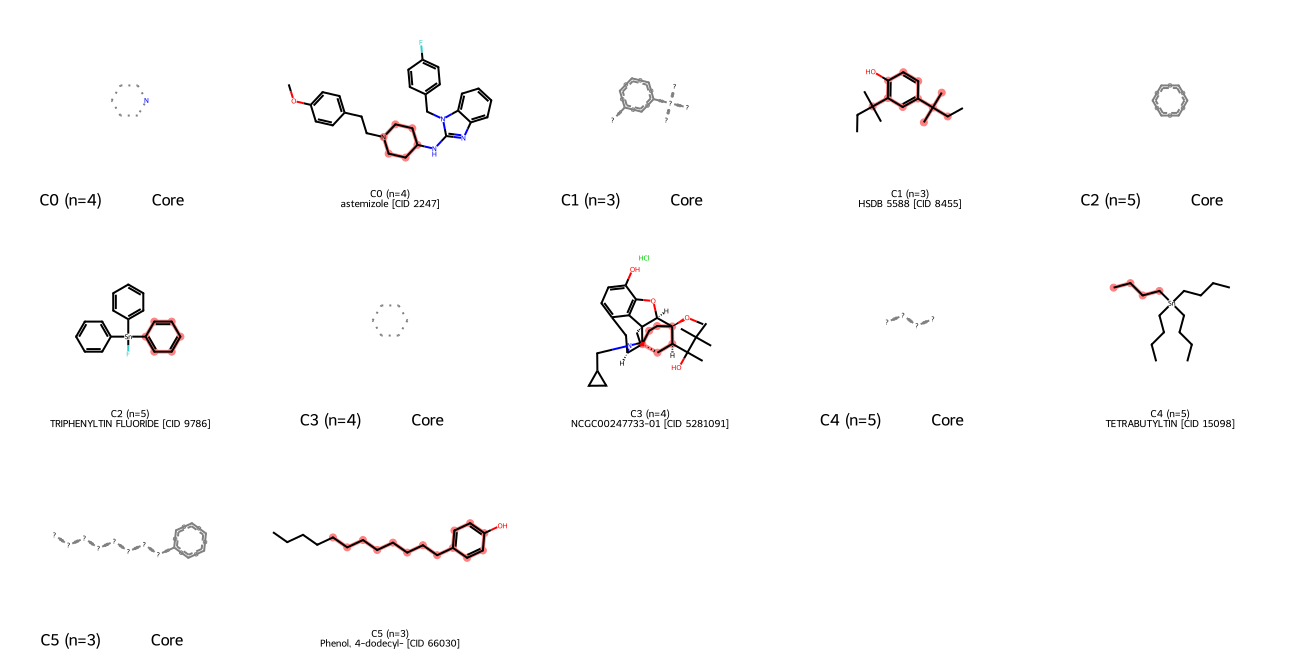

In [19]:
cl_name_66 = draw_cluster_reps(
    g66, {}, title='66 CHO-K1+HepG2 active compounds',
    mols_per_row=5, img_size=(260, 220))

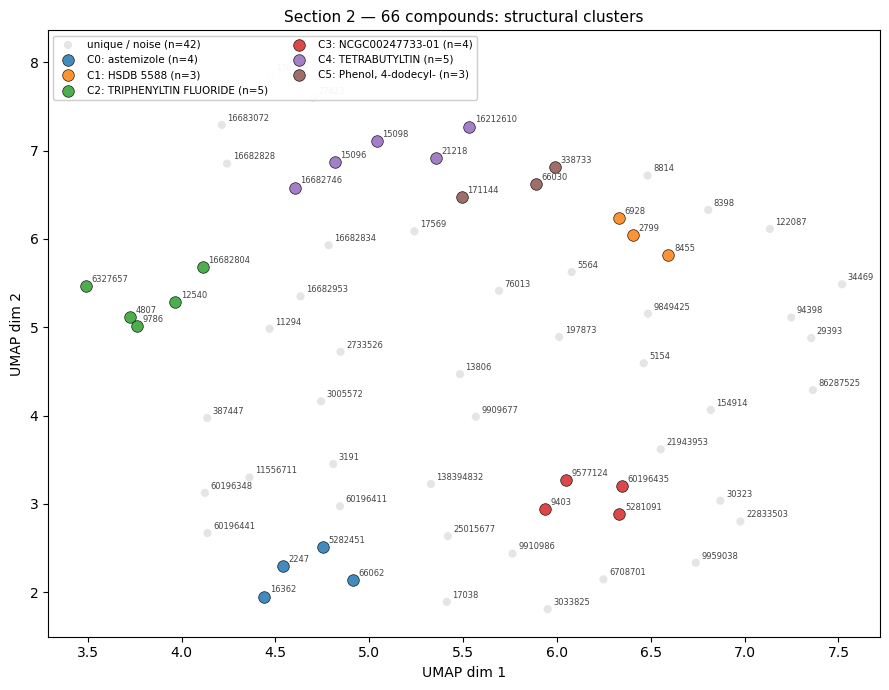

In [20]:
umap_by_cluster(
    g66, cl_name_66,
    title='Section 2 — 66 compounds: structural clusters')

Drawing 30 panels across 6 cluster(s)


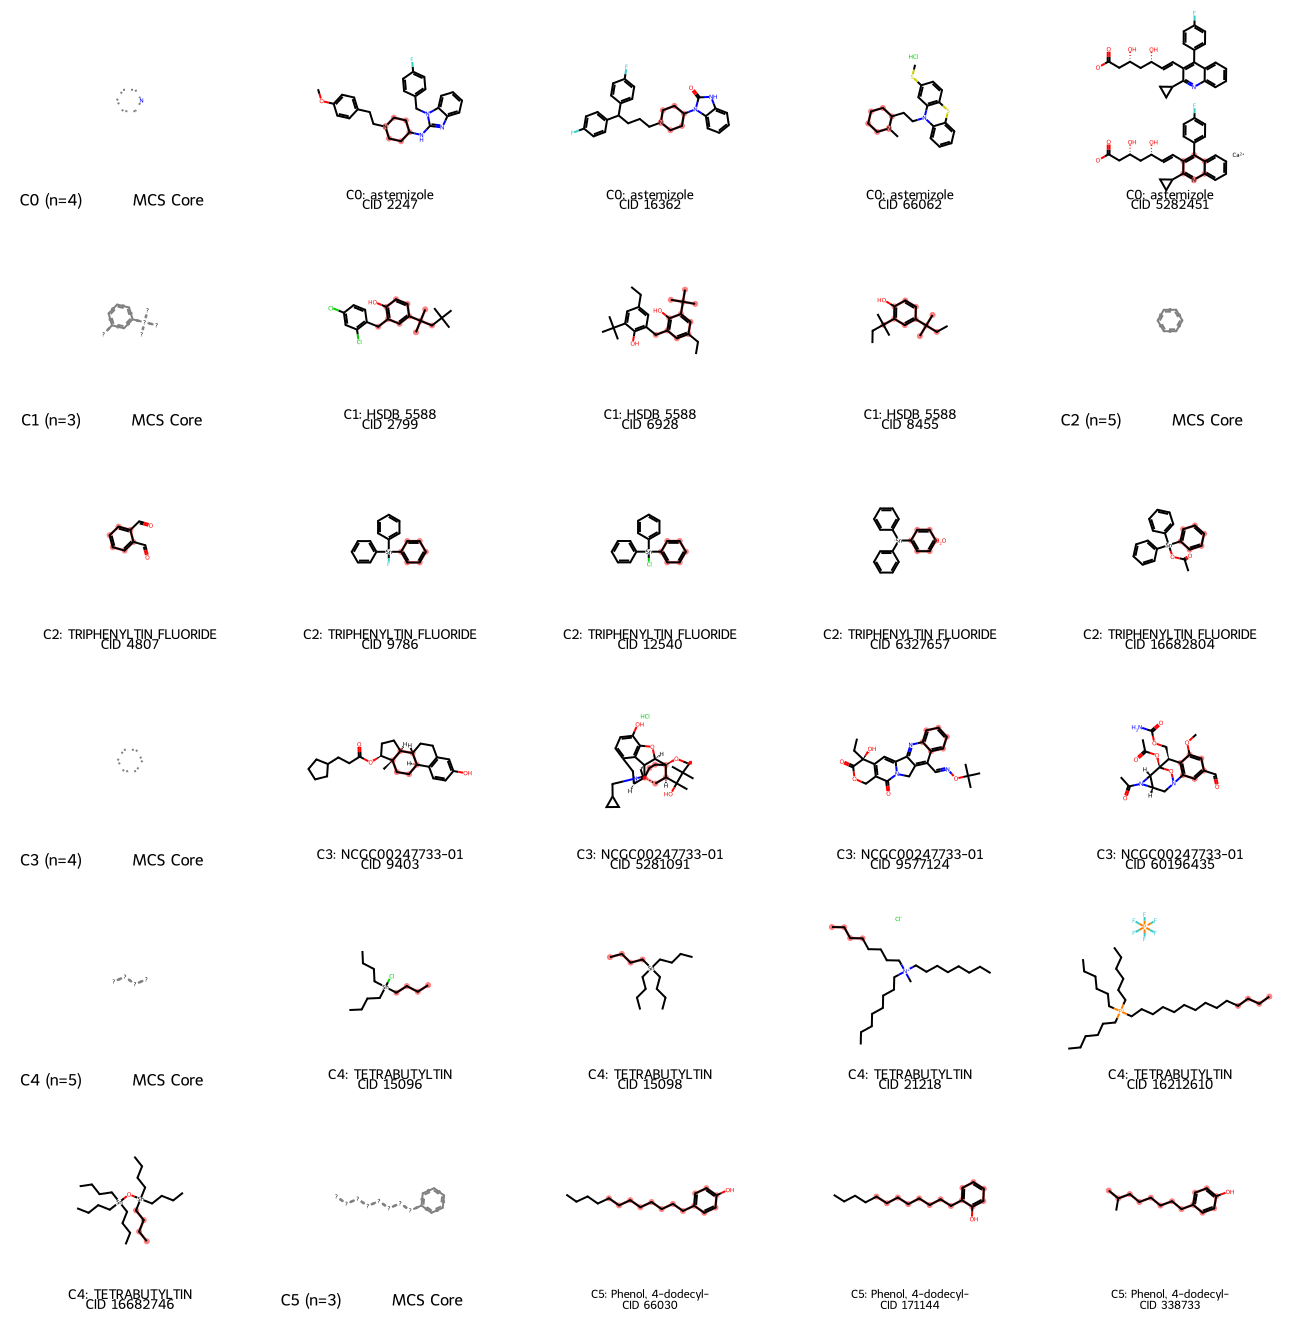

In [21]:
from IPython.display import display

CLUSTERS_66  = None
MAX_PER_CL   = 10
MOLS_PER_ROW = 5

cluster_ids_66 = sorted(c for c in g66['cluster'].unique() if c != -1)
if CLUSTERS_66 is not None:
    cluster_ids_66 = [c for c in cluster_ids_66 if c in CLUSTERS_66]

mols66, legs66, hi66 = [], [], []

for cl in cluster_ids_66:
    sub    = g66[g66['cluster'] == cl].reset_index(drop=True)
    shown  = sub.head(MAX_PER_CL)
    c_mols = shown['mol'].tolist()
    core   = get_mcs_core(c_mols)
    name   = cl_name_66.get(cl, f'Cluster {cl}')

    if core is not None:
        mols66.append(core)
        legs66.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi66.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols66.append(mol)
        legs66.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        hi66.append(list(match))

print(f'Drawing {len(mols66)} panels across {len(cluster_ids_66)} cluster(s)')
if mols66:
    img = Draw.MolsToGridImage(mols66, molsPerRow=MOLS_PER_ROW, subImgSize=(260, 220),
                               legends=legs66, highlightAtomLists=hi66, returnPNG=False)
    display(img)

---
## Section 3 — Combined 170 Compounds (104 + 66)

Do the two groups share structural families? We label each compound by its group and plot together.
Overlapping clusters in the UMAP suggest the same scaffolds appear in both testing contexts.

In [22]:
g104_sub = g104[['PUBCHEM_CID', 'mol', 'fp']].copy()
g104_sub['group'] = '104 (fully tested)'

g66_sub = g66[['PUBCHEM_CID', 'mol', 'fp']].copy()
g66_sub['group'] = '66 (CHO-K1+HepG2)'

g170 = pd.concat([g104_sub, g66_sub], ignore_index=True)
_, fp_matrix_170 = to_fp_matrix(g170['mol'].tolist())
print(f'Combined: {len(g170)} compounds')

Combined: 170 compounds


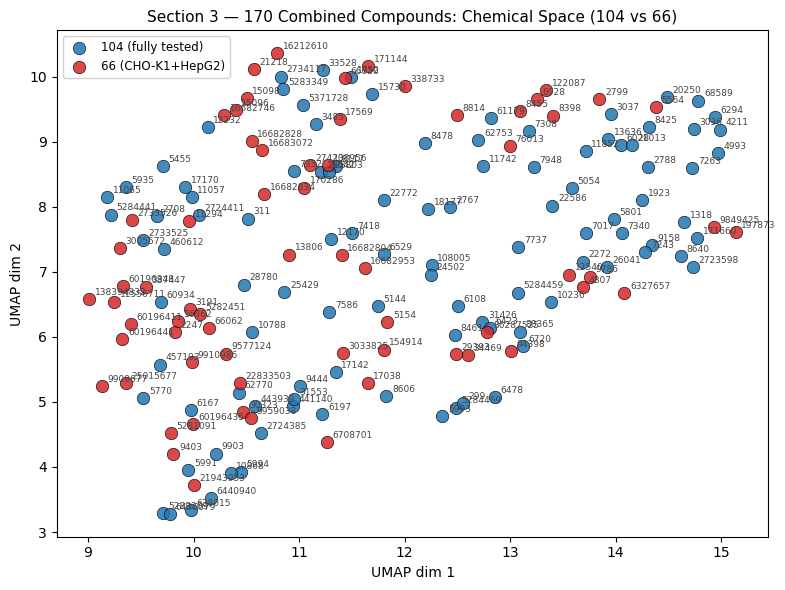

In [23]:
emb_170 = plot_umap(
    fp_matrix_170,
    labels    = g170['group'].tolist(),
    title     = 'Section 3 — 170 Combined Compounds: Chemical Space (104 vs 66)',
    color_map = {'104 (fully tested)': '#1f77b4', '66 (CHO-K1+HepG2)': '#d62728'},
    annotate  = g170['PUBCHEM_CID'].astype(int),
)
g170['umap_x'], g170['umap_y'] = emb_170[:, 0], emb_170[:, 1]

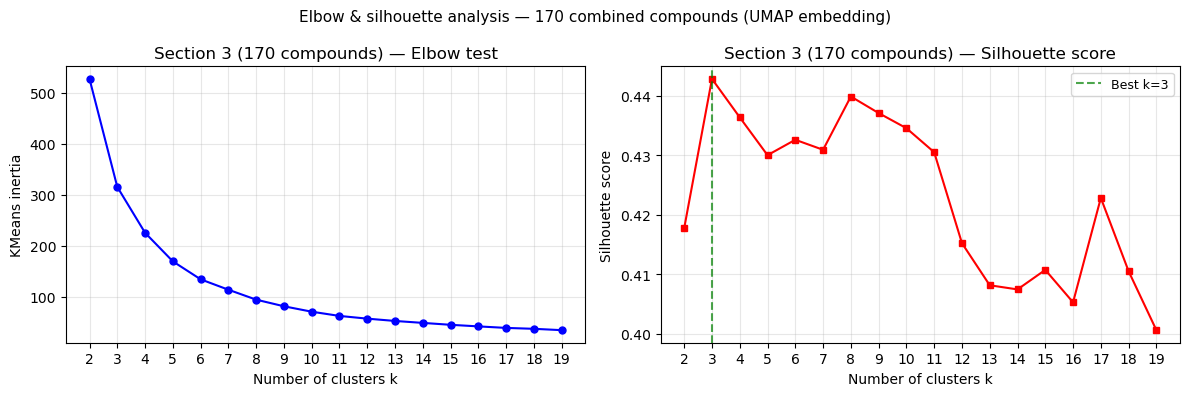

Peak silhouette score at k=3 — DBSCAN cluster count follows below.


In [24]:

# ── Elbow test (KMeans inertia + silhouette) on UMAP embedding ────────────────
K_RANGE_170 = range(2, 20)
inertias_170, silhouettes_170 = [], []

for k in K_RANGE_170:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(emb_170)
    inertias_170.append(km.inertia_)
    silhouettes_170.append(silhouette_score(emb_170, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(list(K_RANGE_170), inertias_170, 'bo-', linewidth=1.5, markersize=5)
ax1.set_xlabel('Number of clusters k')
ax1.set_ylabel('KMeans inertia')
ax1.set_title('Section 3 (170 compounds) — Elbow test')
ax1.set_xticks(list(K_RANGE_170))
ax1.grid(True, alpha=0.3)

ax2.plot(list(K_RANGE_170), silhouettes_170, 'rs-', linewidth=1.5, markersize=5)
ax2.set_xlabel('Number of clusters k')
ax2.set_ylabel('Silhouette score')
ax2.set_title('Section 3 (170 compounds) — Silhouette score')
ax2.set_xticks(list(K_RANGE_170))
ax2.grid(True, alpha=0.3)

best_k_170 = list(K_RANGE_170)[int(np.argmax(silhouettes_170))]
ax2.axvline(best_k_170, color='green', linestyle='--', alpha=0.7, label=f'Best k={best_k_170}')
ax2.legend(fontsize=9)

plt.suptitle('Elbow & silhouette analysis — 170 combined compounds (UMAP embedding)', fontsize=11)
plt.tight_layout()
plt.show()
print(f'Peak silhouette score at k={best_k_170} — DBSCAN cluster count follows below.')

In [25]:
db_170 = DBSCAN(eps=0.45, min_samples=3).fit(emb_170)
g170['cluster'] = db_170.labels_
n_cl_170 = len(set(db_170.labels_)) - (1 if -1 in db_170.labels_ else 0)
print(f'DBSCAN (170): {n_cl_170} clusters, {(db_170.labels_ == -1).sum()} noise points')
print(pd.Series(db_170.labels_).value_counts().sort_index())

# Check which clusters contain BOTH groups (cross-group families)
print('\nCluster composition (both groups?):')
for cl in sorted(c for c in g170['cluster'].unique() if c != -1):
    sub = g170[g170['cluster'] == cl]
    n104 = (sub['group'] == '104 (fully tested)').sum()
    n66  = (sub['group'] == '66 (CHO-K1+HepG2)').sum()
    mixed = ' *** MIXED ***' if n104 > 0 and n66 > 0 else ''
    print(f'  C{cl}: n={len(sub)} | 104-group={n104} | 66-group={n66}{mixed}')

DBSCAN (170): 13 clusters, 10 noise points
-1     10
 0     13
 1      5
 2     20
 3     11
 4     16
 5     17
 6     10
 7     18
 8     11
 9     13
 10     4
 11    19
 12     3
Name: count, dtype: int64

Cluster composition (both groups?):
  C0: n=13 | 104-group=9 | 66-group=4 *** MIXED ***
  C1: n=5 | 104-group=3 | 66-group=2 *** MIXED ***
  C2: n=20 | 104-group=14 | 66-group=6 *** MIXED ***
  C3: n=11 | 104-group=5 | 66-group=6 *** MIXED ***
  C4: n=16 | 104-group=14 | 66-group=2 *** MIXED ***
  C5: n=17 | 104-group=8 | 66-group=9 *** MIXED ***
  C6: n=10 | 104-group=6 | 66-group=4 *** MIXED ***
  C7: n=18 | 104-group=10 | 66-group=8 *** MIXED ***
  C8: n=11 | 104-group=5 | 66-group=6 *** MIXED ***
  C9: n=13 | 104-group=10 | 66-group=3 *** MIXED ***
  C10: n=4 | 104-group=4 | 66-group=0
  C11: n=19 | 104-group=4 | 66-group=15 *** MIXED ***
  C12: n=3 | 104-group=3 | 66-group=0


Fetching PubChem names for 170 combined active compounds...
  Cluster  0 (n= 13)  all-trans-Retinal  [CID 638015]
  Cluster  1 (n=  5)  Fentin acetate  [CID 16682804]
  Cluster  2 (n= 20)  O-PHENYLENEDIAMINE  [CID 7243]
  Cluster  3 (n= 11)  Pentaerythritol triacrylate  [CID 19042]
  Cluster  4 (n= 16)  Dichlorophen  [CID 3037]
  Cluster  5 (n= 17)  Phenol, 4-octyl-  [CID 15730]
  Cluster  6 (n= 10)  EINECS 243-511-6  [CID 88365]
  Cluster  7 (n= 18)  daunorubicin  [CID 30323]
  Cluster  8 (n= 11)  DTXSID7029241  [CID 76013]
  Cluster  9 (n= 13)  MALACHITE GREEN  [CID 11294]
  Cluster 10 (n=  4)  Technical chlordane  [CID 5993]
  Cluster 11 (n= 19)  ebastine  [CID 3191]
  Cluster 12 (n=  3)  DICHLOROACETONITRILE  [CID 18177]


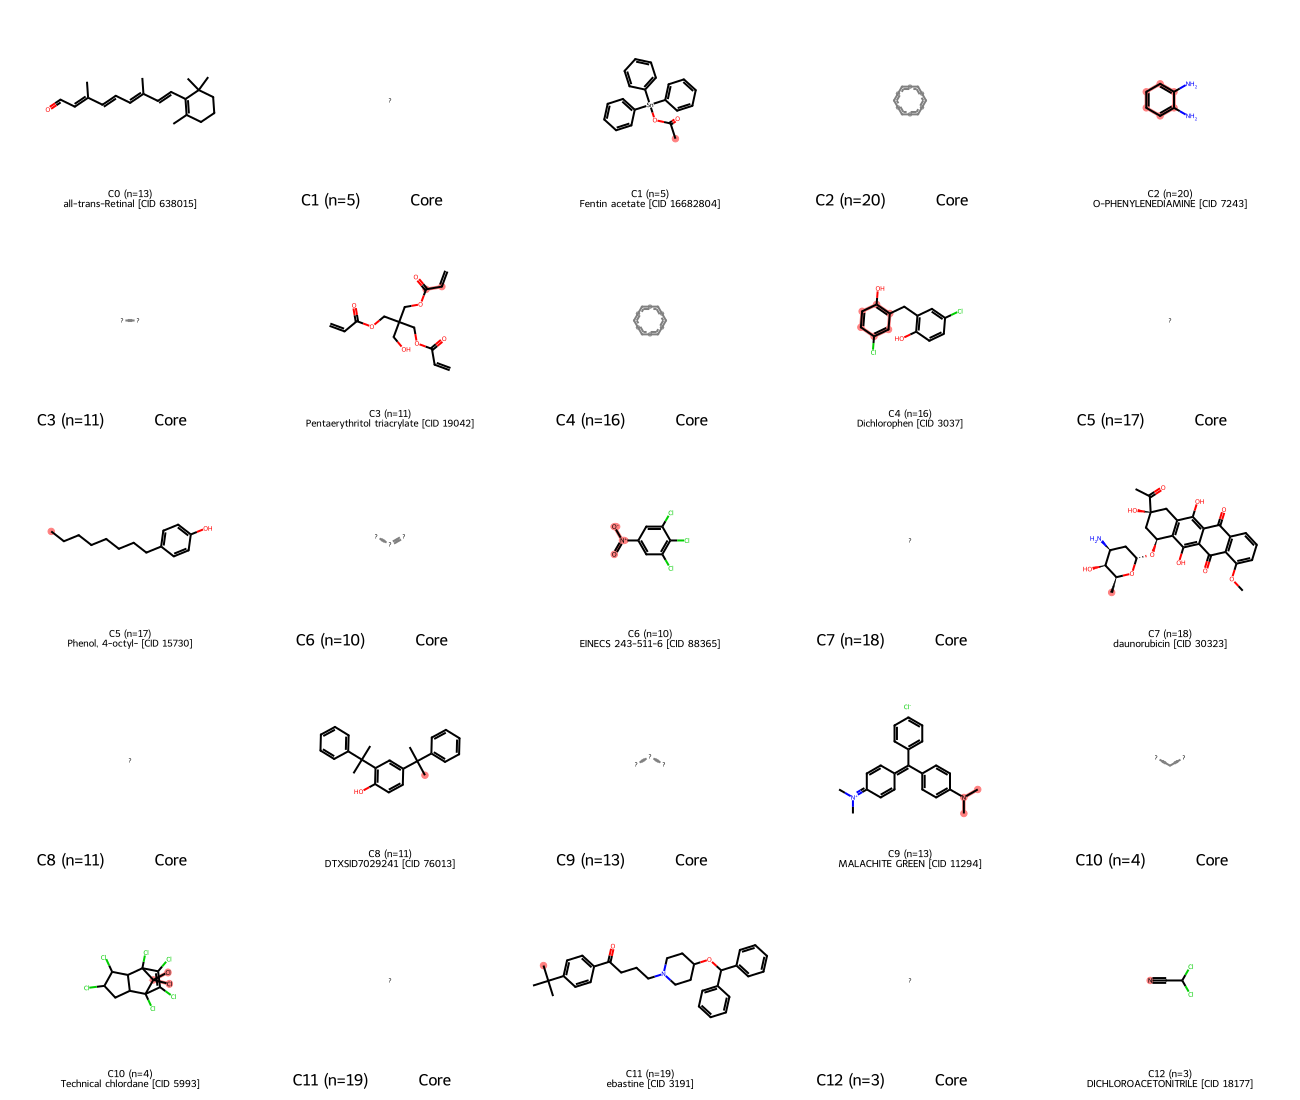

In [26]:
cl_name_170 = draw_cluster_reps(
    g170, {}, title='170 combined active compounds',
    mols_per_row=5, img_size=(260, 220))

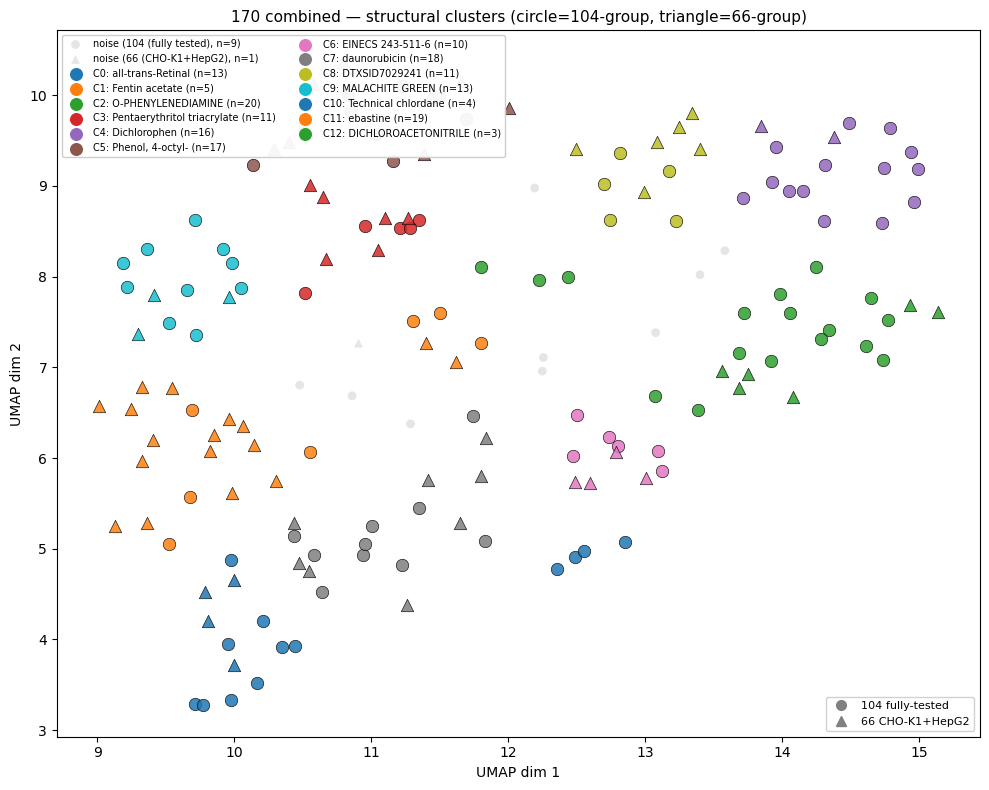

In [27]:
# UMAP coloured by cluster, shape = group
fig, ax = plt.subplots(figsize=(10, 8))
cmap = plt.cm.tab10
markers = {'104 (fully tested)': 'o', '66 (CHO-K1+HepG2)': '^'}

noise = g170[g170['cluster'] == -1]
for grp, mkr in markers.items():
    sub = noise[noise['group'] == grp]
    if len(sub):
        ax.scatter(sub['umap_x'], sub['umap_y'], c='#cccccc',
                   marker=mkr, s=40, edgecolors='none', alpha=0.5,
                   label=f'noise ({grp}, n={len(sub)})')

for cl in sorted(c for c in g170['cluster'].unique() if c != -1):
    sub_cl = g170[g170['cluster'] == cl]
    name   = cl_name_170.get(cl, f'C{cl}')
    for grp, mkr in markers.items():
        sub = sub_cl[sub_cl['group'] == grp]
        if len(sub):
            ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                       marker=mkr, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    ax.scatter([], [], c=[cmap(cl % 10)], s=70, label=f'C{cl}: {name} (n={len(sub_cl)})')

# Legend for markers
from matplotlib.lines import Line2D
custom = [Line2D([0],[0], marker='o', color='grey', linestyle='None', markersize=7, label='104 fully-tested'),
          Line2D([0],[0], marker='^', color='grey', linestyle='None', markersize=7, label='66 CHO-K1+HepG2')]
leg1 = ax.legend(handles=custom, loc='lower right', fontsize=8, framealpha=0.9)
ax.add_artist(leg1)
ax.legend(loc='upper left', fontsize=7, framealpha=0.95, ncol=2)

ax.set_title('170 combined — structural clusters (circle=104-group, triangle=66-group)', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout(); plt.show()

Drawing 125 panels across 13 cluster(s)


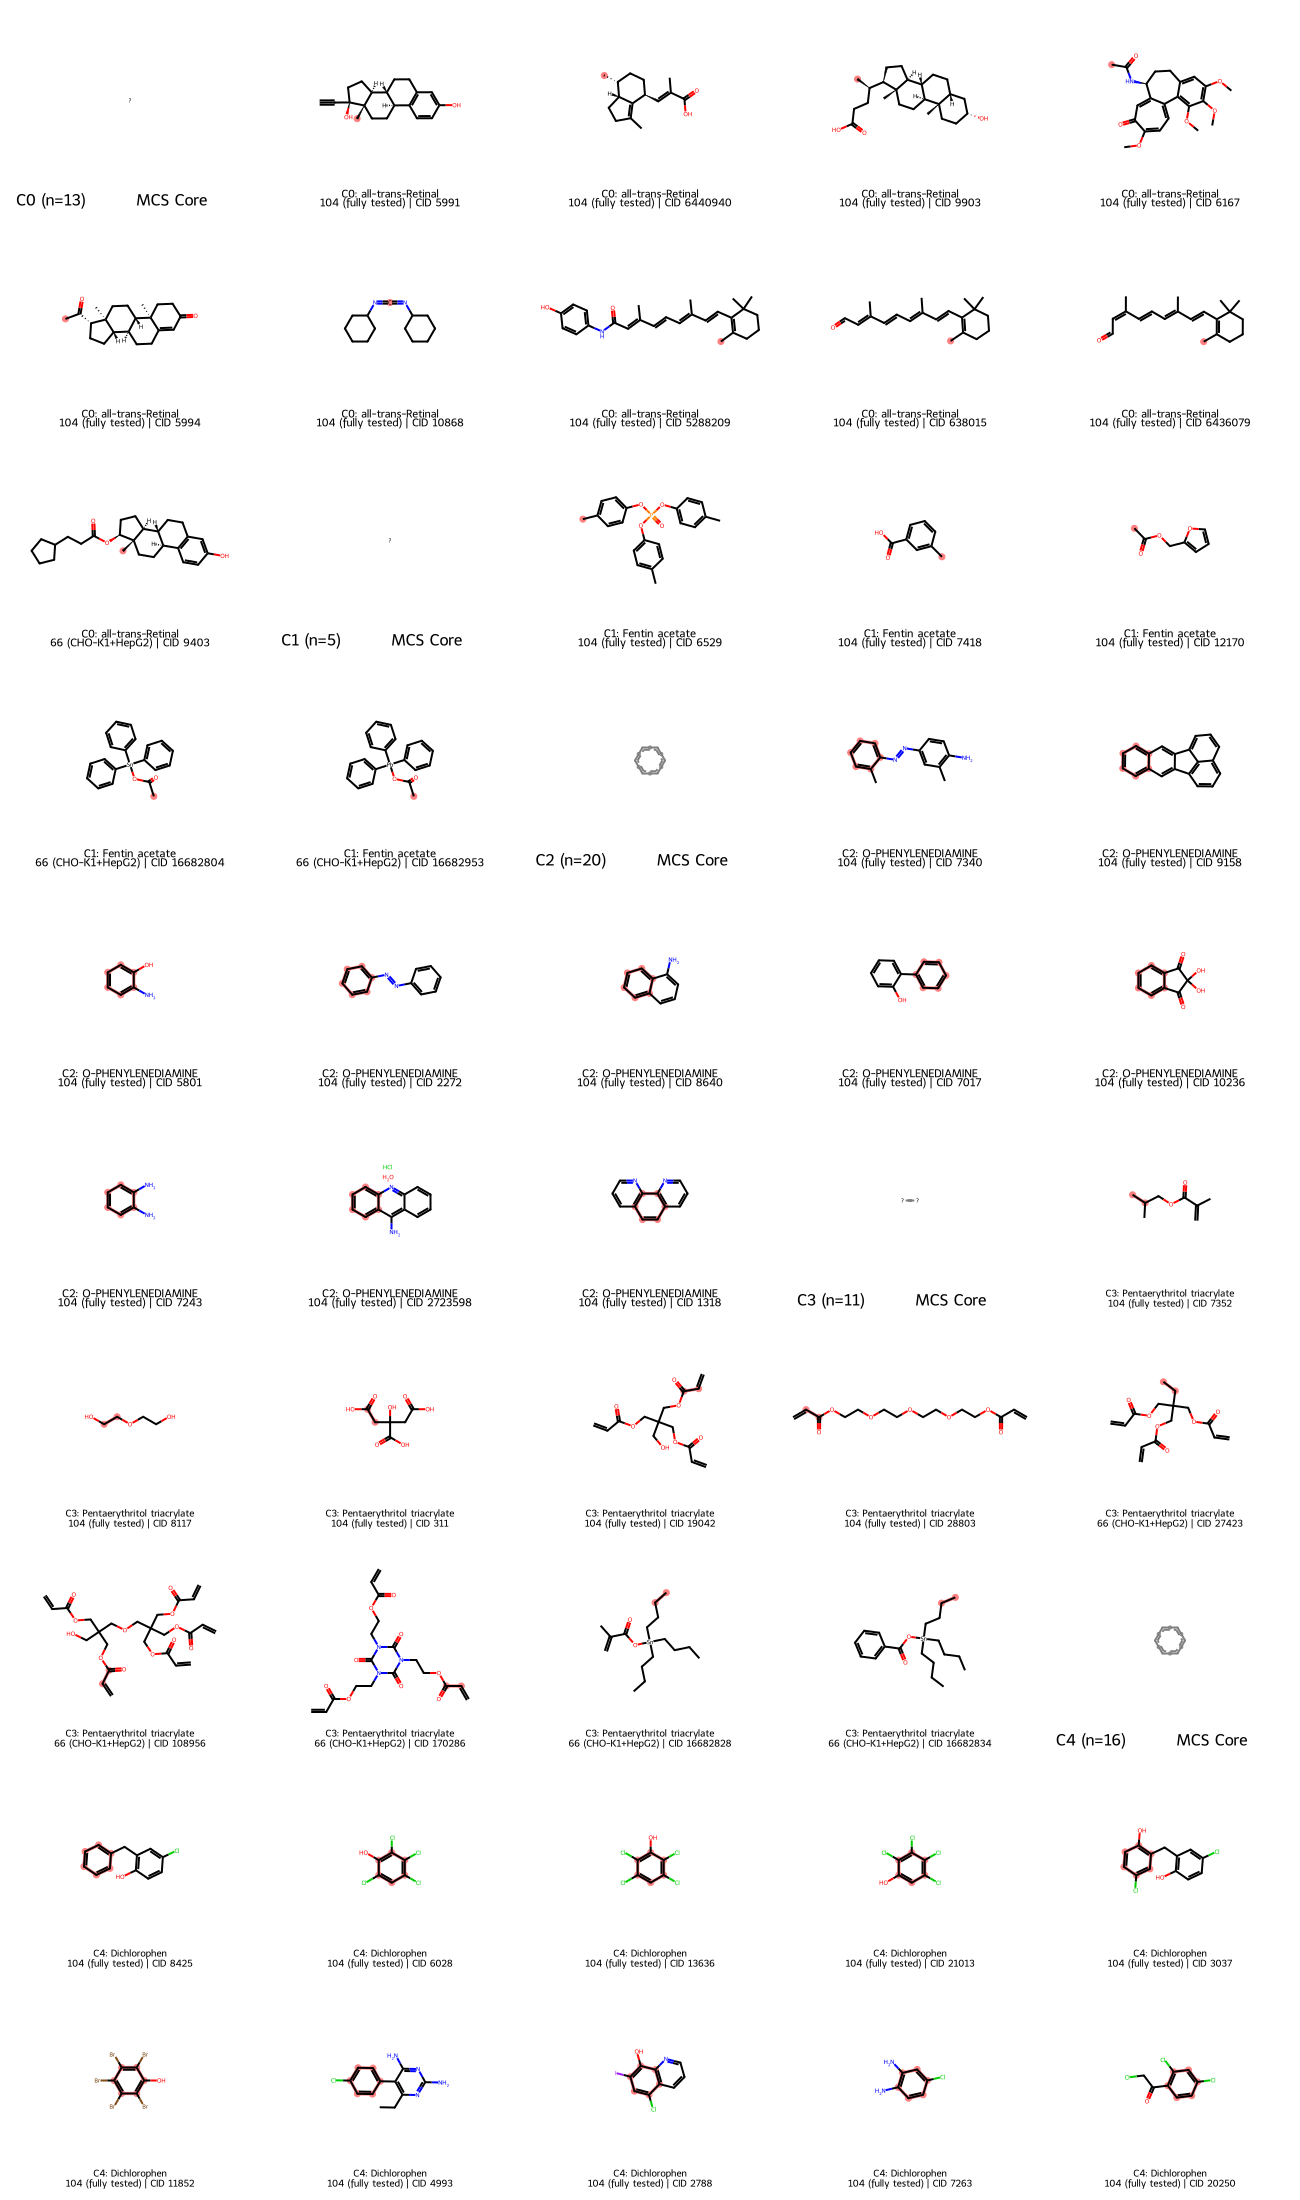

In [28]:
from IPython.display import display

CLUSTERS_170 = None
MAX_PER_CL   = 10
MOLS_PER_ROW = 5

cluster_ids_170 = sorted(c for c in g170['cluster'].unique() if c != -1)
if CLUSTERS_170 is not None:
    cluster_ids_170 = [c for c in cluster_ids_170 if c in CLUSTERS_170]

mols170, legs170, hi170 = [], [], []

for cl in cluster_ids_170:
    sub    = g170[g170['cluster'] == cl].reset_index(drop=True)
    shown  = sub.head(MAX_PER_CL)
    c_mols = shown['mol'].tolist()
    core   = get_mcs_core(c_mols)
    name   = cl_name_170.get(cl, f'Cluster {cl}')

    if core is not None:
        mols170.append(core)
        legs170.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi170.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols170.append(mol)
        legs170.append(f'C{cl}: {name}\n{row["group"]} | CID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        hi170.append(list(match))

print(f'Drawing {len(mols170)} panels across {len(cluster_ids_170)} cluster(s)')
if mols170:
    img = Draw.MolsToGridImage(mols170, molsPerRow=MOLS_PER_ROW, subImgSize=(260, 220),
                               legends=legs170, highlightAtomLists=hi170, returnPNG=False)
    display(img)